# 16 · Figura de curvas ROC del conjunto completo

Une en una sola figura las curvas ROC de CNN-1D, EEGNet, SVM lineal y SVM RBF sobre el mismo conjunto de prueba (12 sujetos, 44.733 épocas).

**Requisitos.** Deben existir en `~/Desktop/TFM` los archivos `roc_cnn1d.npz`, `roc_eegnet.npz`, `roc_svm_lineal.npz` y `roc_svm_rbf.npz`. El último sale del notebook 15 (versión con pesos de clase). Los AUC de las dos redes y de la SVM lineal ya se comprobaron al recalcularlos.

Salida: `images/roc_completo.png`.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

DATA_DIR = os.path.expanduser("~/Desktop/TFM")
IMG_DIR = os.path.expanduser("~/Desktop/TFM/images")
os.makedirs(IMG_DIR, exist_ok=True)
DPI = 150

CURVAS = [
    # (archivo, etiqueta, color, estilo de línea)
    ("roc_cnn1d.npz",       "CNN-1D",     "#1b6ca8", "-"),
    ("roc_eegnet.npz",      "EEGNet",     "#d1495b", "--"),
    ("roc_svm_rbf.npz",     "SVM RBF",    "#2a9d8f", "-."),
    ("roc_svm_lineal.npz",  "SVM lineal", "#6c757d", ":"),
]

datos = {}
for archivo, etiqueta, _, _ in CURVAS:
    ruta = os.path.join(DATA_DIR, archivo)
    assert os.path.exists(ruta), f"Falta {ruta}"
    d = np.load(ruta)
    datos[etiqueta] = (d["fpr"], d["tpr"], float(d["auc"]))
    print(f"{etiqueta:<11} AUC = {float(d['auc']):.4f}")

CNN-1D      AUC = 0.9946
EEGNet      AUC = 0.9946
SVM RBF     AUC = 0.9884
SVM lineal  AUC = 0.9751


## Comprobación numérica
Antes de redactar, conviene saber si las curvas se cruzan. Se compara la tasa de verdaderos positivos de cada modelo con tasas de falsos positivos fijas.

In [2]:
import pandas as pd

puntos = [0.01, 0.02, 0.05, 0.10, 0.20]
filas = []
for etiqueta, (fpr, tpr, auc) in datos.items():
    fila = {"Modelo": etiqueta, "AUC": round(auc, 4)}
    for p in puntos:
        fila[f"TPR@FPR={p:.2f}"] = round(float(np.interp(p, fpr, tpr)), 4)
    filas.append(fila)
tabla_tpr = pd.DataFrame(filas)
tabla_tpr

,Modelo,AUC,TPR@FPR=0.01,TPR@FPR=0.02,TPR@FPR=0.05,TPR@FPR=0.10,TPR@FPR=0.20
0,CNN-1D,0.9946,0.9084,0.9485,0.9830,0.9926,0.9953
1,EEGNet,0.9946,0.9069,0.9463,0.9802,0.9914,0.9951
2,SVM RBF,0.9884,0.8174,0.8855,0.9448,0.9747,0.9902
3,SVM lineal,0.9751,0.6416,0.7925,0.8981,0.9438,0.9756


## Figura
A la izquierda la curva completa y a la derecha una ampliación de la zona de pocos falsos positivos.

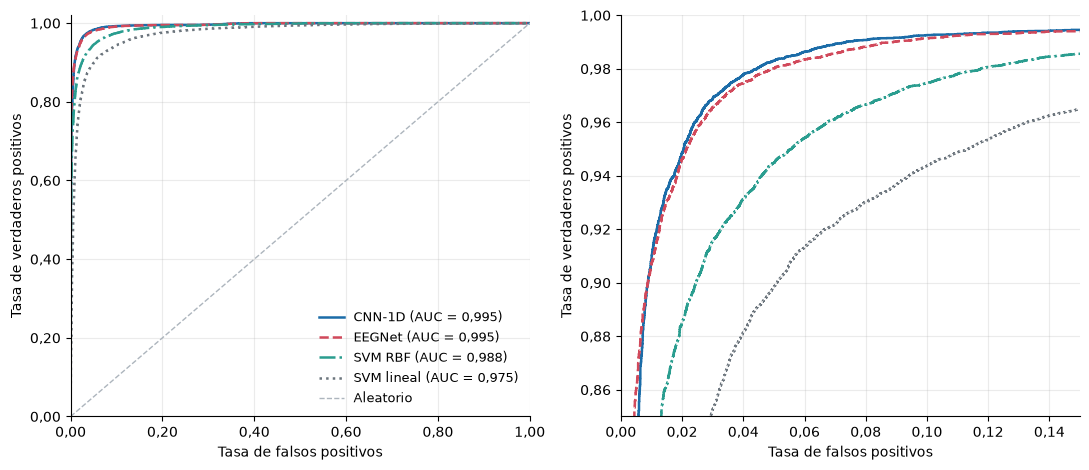

Guardado: C:\Users\alber/Desktop/TFM/images\roc_completo.png


In [3]:
def coma(x, _):
    return f"{x:.2f}".replace(".", ",")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

for ax, zoom in zip(axes, [False, True]):
    for archivo, etiqueta, color, estilo in CURVAS:
        fpr, tpr, auc = datos[etiqueta]
        ax.plot(fpr, tpr, color=color, linestyle=estilo, linewidth=1.8,
                label=f"{etiqueta} (AUC = {auc:.3f})".replace(".", ","))
    if not zoom:
        ax.plot([0, 1], [0, 1], color="#adb5bd", linestyle="--", linewidth=1, label="Aleatorio")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        ax.legend(loc="lower right", fontsize=9, frameon=False)
    else:
        ax.set_xlim(0, 0.15); ax.set_ylim(0.85, 1.0)
    ax.set_xlabel("Tasa de falsos positivos")
    ax.set_ylabel("Tasa de verdaderos positivos")
    ax.xaxis.set_major_formatter(FuncFormatter(coma))
    ax.yaxis.set_major_formatter(FuncFormatter(coma))
    ax.grid(alpha=0.25)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "roc_completo.png"), dpi=DPI, bbox_inches="tight")
plt.show()
print("Guardado:", os.path.join(IMG_DIR, "roc_completo.png"))